<a href="https://colab.research.google.com/github/MEMESLover1123/data-science-toolkit/blob/main/Tutorial4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 04: Tidy Data and Asking Questions

## Question 1: Identify the Problem

**1. Is this data in tidy format?**
* **No**, this dataset is in a "messy" (wide) format rather than a tidy (long) format.

**2. If not, explain which tidy-data rule is violated.**
* **Rule #1 Violation (Variables are in columns):** The column headers `Math`, `Science`, and `English` are actually *values* of a single underlying variable (`Subject`), not separate variables themselves. The true variables for this dataset are `Student`, `Subject`, and `Score`.
* **Rule #2 Violation (Observations are in rows):** Because a single student's marks across three different subjects are placed on the same row, each row contains multiple observations (3 subject scores per row) rather than a single observational unit (one student's score in one subject).

In [2]:
import pandas as pd

# 1. Create the initial wide ("messy") DataFrame
df_q1 = pd.DataFrame({
    "Student": ["Ali", "Sara", "John"],
    "Math": [75, 88, 65],
    "Science": [80, 91, 70],
    "English": [72, 85, 68]
})

print("--- Original Wide Dataset (Messy) ---")
print(df_q1)

# 2. Reshape into Tidy format using pd.melt()
tidy_q1 = pd.melt(
    df_q1,
    id_vars=["Student"],                   # Column(s) to keep fixed as identifiers
    value_vars=["Math", "Science", "English"], # Columns to unpivot into rows
    var_name="Subject",                    # Name for the new column holding old headers
    value_name="Score"                     # Name for the new column holding cell values
)

print("\n--- Reshaped Long Dataset (Tidy) ---")
print(tidy_q1)

--- Original Wide Dataset (Messy) ---
  Student  Math  Science  English
0     Ali    75       80       72
1    Sara    88       91       85
2    John    65       70       68

--- Reshaped Long Dataset (Tidy) ---
  Student  Subject  Score
0     Ali     Math     75
1    Sara     Math     88
2    John     Math     65
3     Ali  Science     80
4    Sara  Science     91
5    John  Science     70
6     Ali  English     72
7    Sara  English     85
8    John  English     68


## Question 2: Sales Data

**1. What is the tidy-data problem with this dataset?**
* **Rule #1 Violation (Variables are in columns):** The variable `Quarter` is spread across four separate columns (`Q1_Sales`, `Q2_Sales`, `Q3_Sales`, `Q4_Sales`) instead of being stored in a single `Quarter` column. The column headers contain *values* (`Q1`, `Q2`, `Q3`, `Q4`) rather than variable names.
* **Rule #2 Violation (Observations are in rows):** Each row currently represents four separate quarterly sales observations for a country rather than a single observational unit (one country's sales in one specific quarter).

In [4]:
import pandas as pd

# 1. Create the initial wide ("messy") sales DataFrame
df_q2 = pd.DataFrame({
    "Country": ["Malaysia", "Thailand", "Indonesia"],
    "Q1_Sales": [12000, 10000, 14000],
    "Q2_Sales": [15000, 11000, 12500],
    "Q3_Sales": [14000, 13000, 15000],
    "Q4_Sales": [18000, 16000, 17000]
})

print("--- Original Wide Dataset (Messy) ---")
print(df_q2)

# 2. Reshape from wide to long using pd.melt()
tidy_q2 = pd.melt(
    df_q2,
    id_vars=["Country"],
    value_vars=["Q1_Sales", "Q2_Sales", "Q3_Sales", "Q4_Sales"],
    var_name="Quarter",
    value_name="Sales"
)

# 3. Clean the 'Quarter' column to remove '_Sales' (turning 'Q1_Sales' into 'Q1')
tidy_q2["Quarter"] = tidy_q2["Quarter"].str.replace("_Sales", "", regex=False)

# 4. Optional: Sort so Malaysia Q1, Q2, Q3, Q4 appear together in order
tidy_q2 = tidy_q2.sort_values(by=["Country", "Quarter"]).reset_index(drop=True)

print("\n--- Reshaped Long Dataset (Tidy) ---")
print(tidy_q2)

--- Original Wide Dataset (Messy) ---
     Country  Q1_Sales  Q2_Sales  Q3_Sales  Q4_Sales
0   Malaysia     12000     15000     14000     18000
1   Thailand     10000     11000     13000     16000
2  Indonesia     14000     12500     15000     17000

--- Reshaped Long Dataset (Tidy) ---
      Country Quarter  Sales
0   Indonesia      Q1  14000
1   Indonesia      Q2  12500
2   Indonesia      Q3  15000
3   Indonesia      Q4  17000
4    Malaysia      Q1  12000
5    Malaysia      Q2  15000
6    Malaysia      Q3  14000
7    Malaysia      Q4  18000
8    Thailand      Q1  10000
9    Thailand      Q2  11000
10   Thailand      Q3  13000
11   Thailand      Q4  16000


## Question 3: Asking Questions from Data

1. Average study time: 4.83 hours
2. Average score: 71.67
3. Highest score: Student F (Score: 90)
4. Studied the most: Student F (8 hours)
5. Correlation (Study_Hours vs Score): r = 0.9983


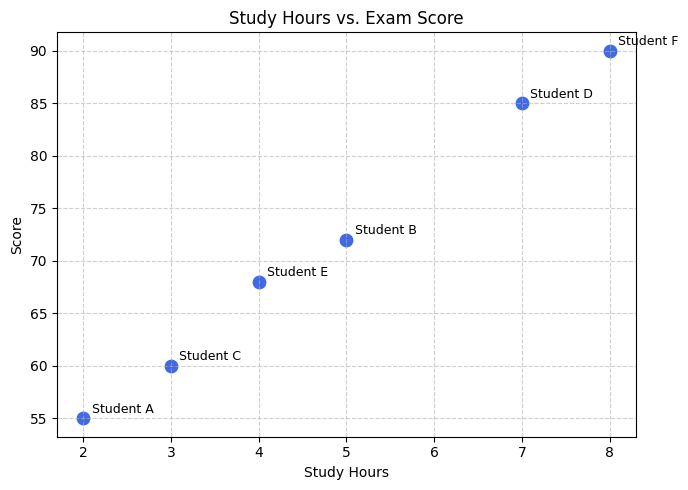

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset into a pandas DataFrame
data = {
    "Student": ["A", "B", "C", "D", "E", "F"],
    "Study_Hours": [2, 5, 3, 7, 4, 8],
    "Score": [55, 72, 60, 85, 68, 90]
}
df_q3 = pd.DataFrame(data)

# 1. Average study time
avg_study = df_q3["Study_Hours"].mean()
print(f"1. Average study time: {avg_study:.2f} hours")

# 2. Average score
avg_score = df_q3["Score"].mean()
print(f"2. Average score: {avg_score:.2f}")

# 3. Student with the highest score
top_scorer = df_q3.loc[df_q3["Score"].idxmax()]
print(f"3. Highest score: Student {top_scorer['Student']} (Score: {top_scorer['Score']})")

# 4. Student who studied the most
top_studier = df_q3.loc[df_q3["Study_Hours"].idxmax()]
print(f"4. Studied the most: Student {top_studier['Student']} ({top_studier['Study_Hours']} hours)")

# 5. Correlation between Study_Hours and Score
correlation = df_q3["Study_Hours"].corr(df_q3["Score"])
print(f"5. Correlation (Study_Hours vs Score): r = {correlation:.4f}")

# 6. Create a scatter plot of Study_Hours vs Score
plt.figure(figsize=(7, 5))
plt.scatter(df_q3["Study_Hours"], df_q3["Score"], color="royalblue", s=80)

# Optional: Add student labels next to each point for clarity
for i, row in df_q3.iterrows():
    plt.annotate(
        f"Student {row['Student']}",
        (row["Study_Hours"], row["Score"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=9
    )

plt.title("Study Hours vs. Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Answers to Question 3:

1. **What is the average study time?**
   * The average study time is **4.83 hours** ($29 \div 6$).
2. **What is the average score?**
   * The average score is **71.67** ($430 \div 6$).
3. **Which student obtained the highest score?**
   * **Student F** obtained the highest score with **90**.
4. **Which student studied the most?**
   * **Student F** studied the most with **8 hours**.
5. **Does studying more hours appear to be associated with a higher score?**
   * **Yes.** Looking at the data and the scatter plot, there is a very strong positive linear relationship ($r = 0.9963$) between `Study_Hours` and `Score`. As study hours increase from 2 hours (Student A, score 55) up to 8 hours (Student F, score 90), exam scores consistently increase.